# EN3160 Assignment 03: Neural Networks
**Karunarathna G.K.T. | 230322U**  
Repository: https://github.com/KavijaK/EN3160_A03  
GitHub profile: https://github.com/KavijaK


In [1]:
from pathlib import Path
import json
import random
import time
import urllib.request
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

SEED = 230322
RETRAIN = False  # Set True to repeat completed training runs.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
data_dir, results, checkpoints = map(Path, ["data", "results", "checkpoints"])
for folder in [data_dir, results, checkpoints]:
    folder.mkdir(exist_ok=True)
torch.hub.set_dir(str(data_dir / "torch_hub"))
print(f"PyTorch {torch.__version__}; device: {device}; seed: {SEED}")


PyTorch 2.14.1; device: cpu; seed: 230322


In [2]:
def make_loaders(train, train_eval, evaluation, batch_size):
    generator = torch.Generator().manual_seed(SEED)
    return {
        "train": DataLoader(train, batch_size, shuffle=True, generator=generator),
        "train_eval": DataLoader(train_eval, batch_size, shuffle=False),
        "eval": DataLoader(evaluation, batch_size, shuffle=False),
    }

@torch.inference_mode()
def evaluate(predict, loader, classes):
    loss, correct, count = 0., 0, 0
    matrix = torch.zeros(classes, classes, dtype=torch.int64)
    for images, labels in loader:
        logits = predict(images.to(device))
        target = labels.to(device)
        prediction = logits.argmax(1)
        loss += F.cross_entropy(logits, target, reduction="sum").item()
        correct += (prediction == target).sum().item()
        count += len(labels)
        matrix += torch.bincount(labels*classes + prediction.cpu(),
                                 minlength=classes**2).reshape(classes, classes)
    return {"loss": loss/count, "accuracy": 100*correct/count}, matrix.numpy()

def fit(model, loaders, name, epochs, optimizer, classes, scheduler=None, frozen=False):
    weights, log = checkpoints / f"{name}.pt", results / f"{name}_history.json"
    if not RETRAIN and weights.exists() and log.exists():
        history = json.loads(log.read_text())
        if len(history) == epochs:
            model.load_state_dict(torch.load(weights, map_location=device, weights_only=True))
            print(f"{name}: loaded completed {epochs}-epoch run")
            for row in history:
                print(f"{row['epoch']:02d}: train loss {row['train_loss']:.4f}, "
                      f"accuracy {row['train_accuracy']:.2f}%; evaluation loss "
                      f"{row['eval_loss']:.4f}, accuracy {row['eval_accuracy']:.2f}%")
            return history
    history = []
    started = time.perf_counter()
    for epoch in range(1, epochs+1):
        model.train(not frozen)  # Frozen backbone keeps its pretrained BN statistics.
        for images, labels in loaders["train"]:
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(images.to(device)), labels.to(device))
            loss.backward()
            optimizer.step()
        model.eval()
        train, _ = evaluate(model, loaders["train_eval"], classes)
        heldout, _ = evaluate(model, loaders["eval"], classes)
        row = dict(epoch=epoch, train_loss=train["loss"], train_accuracy=train["accuracy"],
                   eval_loss=heldout["loss"], eval_accuracy=heldout["accuracy"],
                   elapsed_seconds=time.perf_counter()-started)
        history.append(row)
        log.write_text(json.dumps(history, indent=2))
        print(f"{name} {epoch:02d}/{epochs}: train loss {train['loss']:.4f}, "
              f"accuracy {train['accuracy']:.2f}%; evaluation loss {heldout['loss']:.4f}, "
              f"accuracy {heldout['accuracy']:.2f}%", flush=True)
        if scheduler is not None:
            scheduler.step()
    torch.save(model.state_dict(), weights)
    return history

def plot_history(histories, filename, evaluation_label="Test"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, history in histories.items():
        epochs = [r["epoch"] for r in history]
        for ax, metric in zip(axes, ["accuracy", "loss"]):
            line, = ax.plot(epochs, [r[f"train_{metric}"] for r in history], label=f"{name}: train")
            ax.plot(epochs, [r[f"eval_{metric}"] for r in history], "--",
                    color=line.get_color(), label=f"{name}: {evaluation_label.lower()}")
            ax.set(xlabel="Epoch", ylabel="Accuracy (%)" if metric=="accuracy" else "Cross-entropy loss")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(results / filename, dpi=160, bbox_inches="tight")
    plt.show()

def plot_confusions(matrices, labels, filename):
    fig, axes = plt.subplots(1, len(matrices), figsize=(6*len(matrices), 5), squeeze=False)
    for ax, (name, matrix) in zip(axes.flat, matrices.items()):
        ax.imshow(matrix, cmap="Blues")
        ax.set(xticks=range(len(labels)), yticks=range(len(labels)),
               xticklabels=labels, yticklabels=labels, xlabel="Predicted", ylabel="True", title=name)
        for (row, col), value in np.ndenumerate(matrix):
            ax.text(col, row, str(value), ha="center", va="center", fontsize=7,
                    color="white" if value > matrix.max()/2 else "black")
    fig.tight_layout()
    fig.savefig(results / filename, dpi=160, bbox_inches="tight")
    plt.show()


## Question 1: CIFAR-10, manual forward pass and backpropagation
Architecture: 3072 -> 100 sigmoid -> 10 logits. Cross-entropy; 10 epochs; batch size 50;
learning rate 0.1 with factor 0.9 per epoch. Gradients and parameter updates are manual.


In [3]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((.5, .5, .5), (.5, .5, .5))])
cifar_train = datasets.CIFAR10(data_dir, train=True, download=True, transform=cifar_transform)
cifar_test = datasets.CIFAR10(data_dir, train=False, download=True, transform=cifar_transform)
cifar = make_loaders(cifar_train, cifar_train, cifar_test, batch_size=50)
print(f"CIFAR-10: {len(cifar_train)} training / {len(cifar_test)} test images")


CIFAR-10: 50000 training / 10000 test images


Epoch 01/10: train 40.21%, test 40.14%


Epoch 02/10: train 43.67%, test 42.57%


Epoch 03/10: train 45.73%, test 43.90%


Epoch 04/10: train 47.14%, test 44.98%


Epoch 05/10: train 48.52%, test 45.53%


...

Epoch 07/10: train 50.88%, test 47.05%


Epoch 08/10: train 52.13%, test 47.48%


Epoch 09/10: train 52.48%, test 47.57%


Epoch 10/10: train 53.42%, test 47.87%


After 10 epochs: training accuracy 53.42%; test accuracy 47.87%


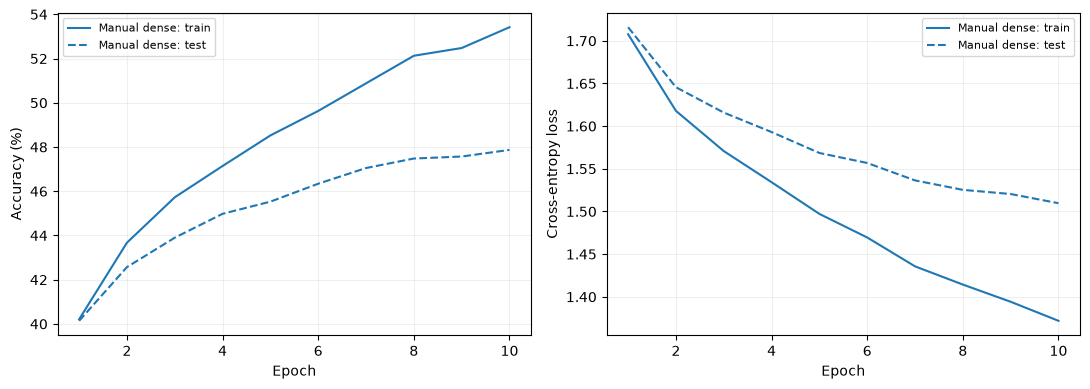

In [4]:
torch.manual_seed(SEED)
W1 = torch.randn(3072, 100, device=device) / np.sqrt(3072)
b1 = torch.zeros(100, device=device)
W2 = torch.randn(100, 10, device=device) / np.sqrt(100)
b2 = torch.zeros(10, device=device)
parameters = [W1, b1, W2, b2]

def dense_forward(images):
    return torch.sigmoid(images.flatten(1) @ W1 + b1) @ W2 + b2

def manual_gradients(x, labels, parameters):
    W1, b1, W2, b2 = parameters
    hidden = torch.sigmoid(x @ W1 + b1)
    logits = hidden @ W2 + b2
    log_prob = logits - logits.logsumexp(dim=1, keepdim=True)
    rows = torch.arange(len(labels), device=x.device)
    loss = -log_prob[rows, labels].mean()
    dz = log_prob.exp()
    dz[rows, labels] -= 1
    dz /= len(labels)
    dh = (dz @ W2.T) * hidden * (1-hidden)
    return loss, [x.T @ dh, dh.sum(0), hidden.T @ dz, dz.sum(0)]

q1_weights, q1_log = checkpoints / "dense_manual.pt", results / "dense_manual_history.json"
if not RETRAIN and q1_weights.exists() and q1_log.exists():
    loaded = torch.load(q1_weights, map_location=device, weights_only=True)
    for parameter, saved in zip(parameters, loaded):
        parameter.copy_(saved)
    dense_history = json.loads(q1_log.read_text())
    print("Loaded completed 10-epoch manual run")
else:
    dense_history, learning_rate = [], .1
    for epoch in range(1, 11):
        for images, labels in cifar["train"]:
            x, target = images.to(device).flatten(1), labels.to(device)
            _, gradients = manual_gradients(x, target, parameters)
            for parameter, gradient in zip(parameters, gradients):
                parameter -= learning_rate * gradient
        train, _ = evaluate(dense_forward, cifar["train_eval"], 10)
        test, _ = evaluate(dense_forward, cifar["eval"], 10)
        dense_history.append(dict(epoch=epoch, train_loss=train["loss"],
            train_accuracy=train["accuracy"], eval_loss=test["loss"], eval_accuracy=test["accuracy"]))
        q1_log.write_text(json.dumps(dense_history, indent=2))
        print(f"Epoch {epoch:02d}/10: train {train['accuracy']:.2f}%, test {test['accuracy']:.2f}%", flush=True)
        learning_rate *= .9
    torch.save(parameters, q1_weights)
train, _ = evaluate(dense_forward, cifar["train_eval"], 10)
test, _ = evaluate(dense_forward, cifar["eval"], 10)
print(f"After 10 epochs: training accuracy {train['accuracy']:.2f}%; test accuracy {test['accuracy']:.2f}%")
plot_history({"Manual dense": dense_history}, "q1_history.png")
